# Week 7 — Regression and Statistical Modeling with R

**Nama:** Cheisa Billy Putra Antoni<br>
**NIM:** 25/566096/PA/23888

**Course:** Statistical Computation with R Software  
**Topic:** Linear regression, model interpretation, prediction, diagnostics, and multiple regression  
**Environment:** Google Colab with an R runtime

## Learning objectives
By the end of this practical session, you should be able to:

1. Explain the purpose of statistical modeling.
2. Fit simple linear regression using `lm()`.
3. Interpret regression coefficients and confidence intervals.
4. Explain residuals and $R^2$.
5. Make predictions and distinguish confidence from prediction intervals.
6. Diagnose common regression assumptions.
7. Extend a model to multiple linear regression.
8. Include categorical predictors.
9. Distinguish association from causation.
10. Communicate regression results appropriately.


## Computational philosophy

$$\boxed{\text{Data}\rightarrow\text{Model}\rightarrow\text{Fit}\rightarrow\text{Diagnose}\rightarrow\text{Interpret}\rightarrow\text{Predict}}$$

A regression model is not simply an R command. Statistical reasoning comes first; R performs the numerical calculations and helps diagnose the model.


# 1. Create an example dataset

Suppose we investigate whether **study hours** are associated with **exam scores**. We simulate a dataset so the data-generating mechanism is known.


In [1]:
set.seed(2026)
n <- 100
study_hours <- runif(n, 2, 15)
score <- 45 + 3.0 * study_hours + rnorm(n, 0, 8)
data <- data.frame(study_hours, score)
head(data)


,study_hours,score
,<dbl>,<dbl>
1,11.082755,68.88908
2,9.234897,71.05509
3,3.821819,49.02058
4,5.714403,65.73839
5,9.219797,67.50094
6,2.326705,50.12873


In [2]:
str(data)
summary(data)
dim(data)


'data.frame':	100 obs. of  2 variables:
 $ study_hours: num  11.08 9.23 3.82 5.71 9.22 ...
 $ score      : num  68.9 71.1 49 65.7 67.5 ...


  study_hours         score       
 Min.   : 2.016   Min.   : 39.18  
 1st Qu.: 5.019   1st Qu.: 59.09  
 Median : 7.984   Median : 70.09  
 Mean   : 8.293   Mean   : 69.66  
 3rd Qu.:11.392   3rd Qu.: 79.46  
 Max.   :14.708   Max.   :109.22  

[1] 100   2

# 2. Explore the relationship

Always inspect data before modeling. A scatterplot can reveal approximate linearity, outliers, clusters, changing variability, or nonlinear patterns.


[1] 0.8219499

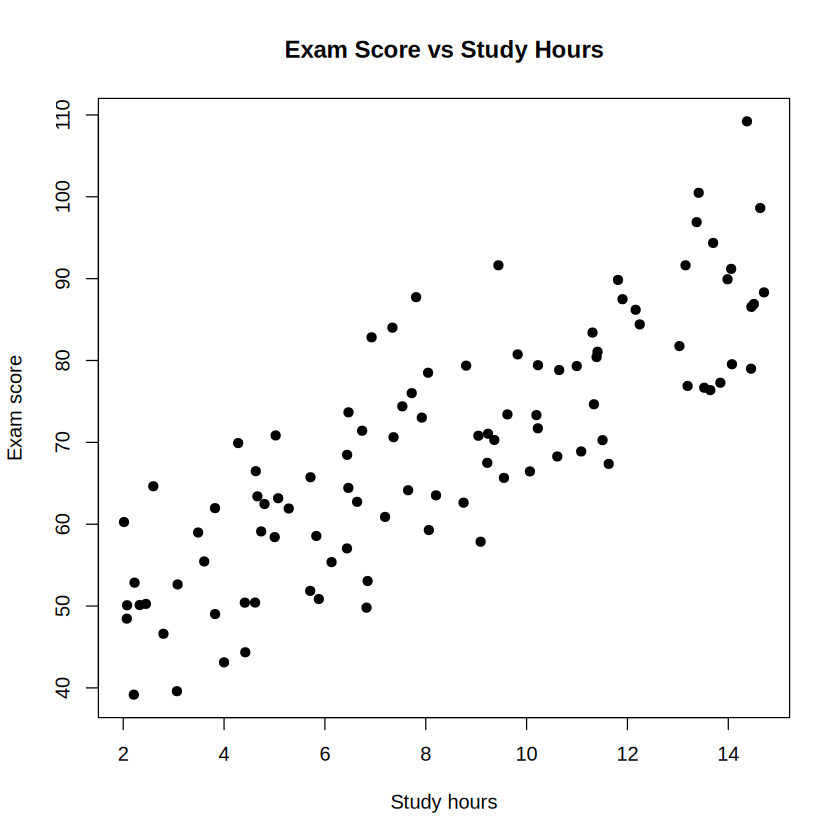

In [3]:
plot(data$study_hours, data$score, pch=19,
     xlab="Study hours", ylab="Exam score",
     main="Exam Score vs Study Hours")

cor(data$study_hours, data$score)


## Exercise 1 — Explore the data

1. Calculate the mean and standard deviation of `study_hours`.
2. Calculate the mean and standard deviation of `score`.
3. Calculate the correlation.
4. Inspect the scatterplot.
5. Write two or three sentences describing the apparent relationship.

**Important:** Do not claim that study hours *cause* higher scores merely from this observational relationship.


In [4]:
# Your solution
mean(data$study_hours)
sd(data$study_hours)
mean(data$score)
sd(data$score)
cor(data$study_hours, data$score)


[1] 8.292518

[1] 3.799645

[1] 69.66391

[1] 14.72311

[1] 0.8219499

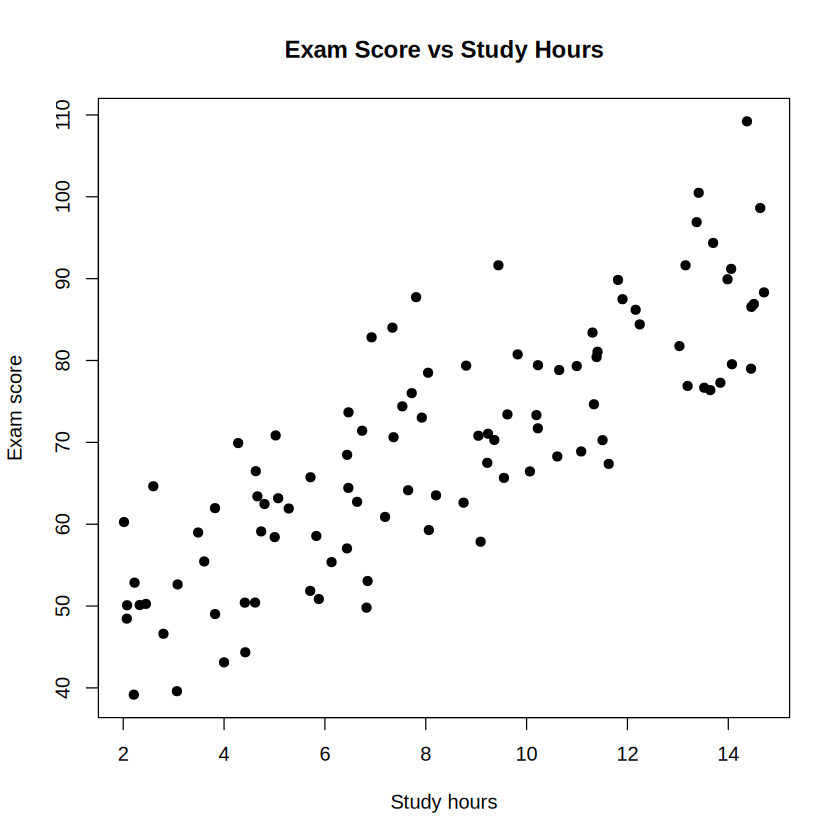

In [5]:
plot(data$study_hours, data$score, pch=19,
     xlab="Study hours", ylab="Exam score",
     main="Exam Score vs Study Hours")

Korelasi antara variabel study_hours dan score memiliki hubungan yang sangat kuat dengan koefisien korelasi sebesar 0,82194 (82,19%) serta memiliki arah positif. Artinya, saat variabel study_hours meningkat menyebabkan rata-rata variabel score juga ikut meningkat. Hal ini juga diperkuat dengan tampilan scatter plot yang membentuk pola linear yang semakin naik seiring dengan bertambahnya variabel study_hours maupun variabel score.

# 3. Fit a simple linear regression model

$$Y_i=\beta_0+\beta_1X_i+\varepsilon_i.$$

Use `lm(response ~ predictor, data=...)`.


In [6]:
model1 <- lm(score ~ study_hours, data=data)
model1
summary(model1)



Call:
lm(formula = score ~ study_hours, data = data)

Coefficients:
(Intercept)  study_hours  
     43.253        3.185  



Call:
lm(formula = score ~ study_hours, data = data)

Residuals:
     Min       1Q   Median       3Q      Max 
-15.1832  -7.0177  -0.4439   5.5299  20.1993 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)  43.2527     2.0318   21.29   <2e-16 ***
study_hours   3.1849     0.2229   14.29   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 8.428 on 98 degrees of freedom
Multiple R-squared:  0.6756,	Adjusted R-squared:  0.6723 
F-statistic: 204.1 on 1 and 98 DF,  p-value: < 2.2e-16


## Interpreting the coefficients

- **Intercept:** expected outcome when the predictor equals zero, when that value is meaningful.
- **Slope:** expected average change in the outcome for a one-unit increase in the predictor.

For example, a slope near 3 means that each additional hour of study is associated with an average increase of about 3 score points. This is an association, not automatically a causal effect.


In [7]:
coef(model1)
coef(model1)[1]  # intercept
coef(model1)[2]  # slope


(Intercept) study_hours 
  43.252697    3.184945

(Intercept) 
    43.2527

study_hours 
   3.184945

# 4. Least squares, fitted values, and residuals

Ordinary least squares minimizes

$$S(\beta_0,\beta_1)=\sum_i(y_i-\beta_0-\beta_1x_i)^2.$$

The fitted value is $\hat y_i$ and the residual is $e_i=y_i-\hat y_i$.


In [8]:
fitted_values <- fitted(model1)
residuals <- resid(model1)
head(fitted_values)
head(residuals)
sum(residuals)


1        2        3        4        5        6 
78.55066 72.66533 55.42498 61.45276 72.61724 50.66312

1          2          3          4          5          6 
-9.6615859 -1.6102457 -6.4044055  4.2856337 -5.1163035 -0.5343906

[1] 1.323941e-14

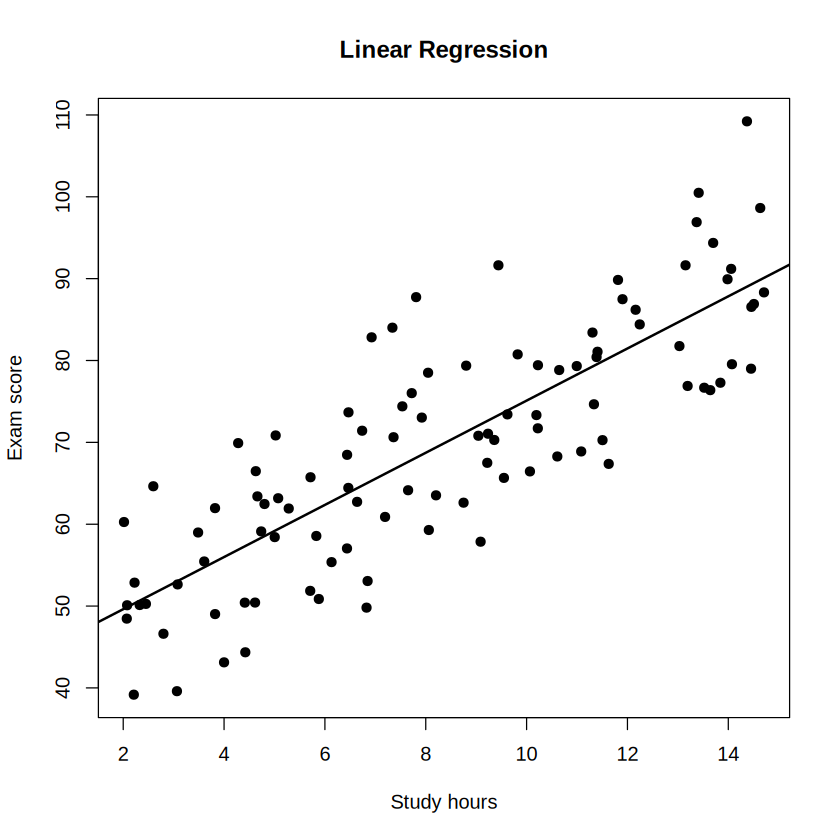

In [9]:
plot(data$study_hours, data$score, pch=19,
     xlab="Study hours", ylab="Exam score",
     main="Linear Regression")
abline(model1, lwd=2)


# 5. Confidence intervals and hypothesis test for the slope

For the slope, a common test is

$$H_0:\beta_1=0 \quad vs. \quad H_1:\beta_1\ne0.$$

Use `confint()` to obtain a confidence interval. The interval should be interpreted in the context of repeated sampling and the fitted model.


In [10]:
confint(model1, level=0.95)


,2.5 %,97.5 %
(Intercept),39.220705,47.284688
study_hours,2.742533,3.627357


## Exercise 2 — Interpret the slope interval

1. Identify the lower and upper limits.
2. Explain the interval in context.
3. Determine whether 0 is inside the interval.
4. Relate this to the hypothesis test for the slope.


1. Nilai intercept memiliki nilai interval konfidensi dengan batas bawah sebesar 39,220705	dan batas atas sebesar 47,284688. Sedangkan, nilai Koefisien variabel study_hours memiliki nilai interval dengan batas bawah sebesar	2,742533 dan batas atas sebesar	3,627357.
2. Artinya peneliti yakin bahwa 95% nilai asli dari intercept maupun koefisien variabel study_hours berada pada rentang interval tersebut.
3. Interval konfidensi pada intercept maupun koefisien variabel study_hours tidak memuat angka 0 didalamnya.
4. Berdasarkan jawaban pada nomor 3, maka angka 0 yang tidak berada pada interval ini menyebabkan penolakan hipotesis nol untuk pengujiann signifikansi intercept maupun koefisien variabel study_hours. Sehingga, dapat disimpulkan bahwa intercept dan koefisien variabel study_hours ini signifikan terhadap model regresi linear.

# 6. Coefficient of determination: $R^2$

$$R^2=1-\frac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2}.$$

$R^2$ measures the proportion of variation in the response explained by the fitted linear model. A high $R^2$ does not prove causation, and a low $R^2$ does not automatically make a model useless.


In [11]:
summary(model1)$r.squared
summary(model1)$adj.r.squared


[1] 0.6756016

[1] 0.6722915

# 7. Prediction

A **confidence interval** describes uncertainty about the mean response. A **prediction interval** describes uncertainty about a new individual observation and is therefore wider.


In [12]:
new_student <- data.frame(study_hours=10)

predict(model1, newdata=new_student, interval="confidence", level=0.95)
predict(model1, newdata=new_student, interval="prediction", level=0.95)


,fit,lwr,upr
1,75.10215,73.26689,76.93741


,fit,lwr,upr
1,75.10215,58.27594,91.92835


## Exercise 3 — Prediction

Predict scores for students studying 5, 10, and 12 hours. For each value, calculate both a confidence interval for the mean and a prediction interval for an individual student. Explain why the prediction interval is wider.


In [13]:
new_students <- data.frame(study_hours=c(5,10,12))
predict(model1, newdata=new_students, interval="confidence")
predict(model1, newdata=new_students, interval="prediction")


,fit,lwr,upr
1,59.17742,56.95946,61.39538
2,75.10215,73.26689,76.93741
3,81.47204,79.12941,83.81466


,fit,lwr,upr
1,59.17742,42.30518,76.04966
2,75.10215,58.27594,91.92835
3,81.47204,64.58296,98.36111


Diperoleh nilai Interval Konfidensi (CI) dan juga Prediksi Interval (PI) dari skor nilai siswa. Berdasarkan output di atas, diperoleh informasi bahwa nilai PI lebih lebar intervalnya dari pada nilai CI. Hal ini dikarenakan tujuan dari kedua nilai ini berbeda. Nilai CI untuk memprediksi secara rata-rata nilai skor siswa saat prdiktornya sama dengan suatu nilai. Sedangkan, PI lebih untuk memprediksi satu target skor nilai siswa berdasarkan prdiktornya. Nilai yang berbeda ini disebabkan oleh rumus Standard Error yang berbeda pada CI dan juga PI.

# 8. Residual diagnostics

Important assumptions include:

1. **Linearity** of the mean relationship.
2. **Independence** of observations/errors, as appropriate for the design.
3. **Constant variance** of errors.
4. **Approximate normality of errors**, particularly for small-sample inference.

Diagnostics should be interpreted in context rather than mechanically.


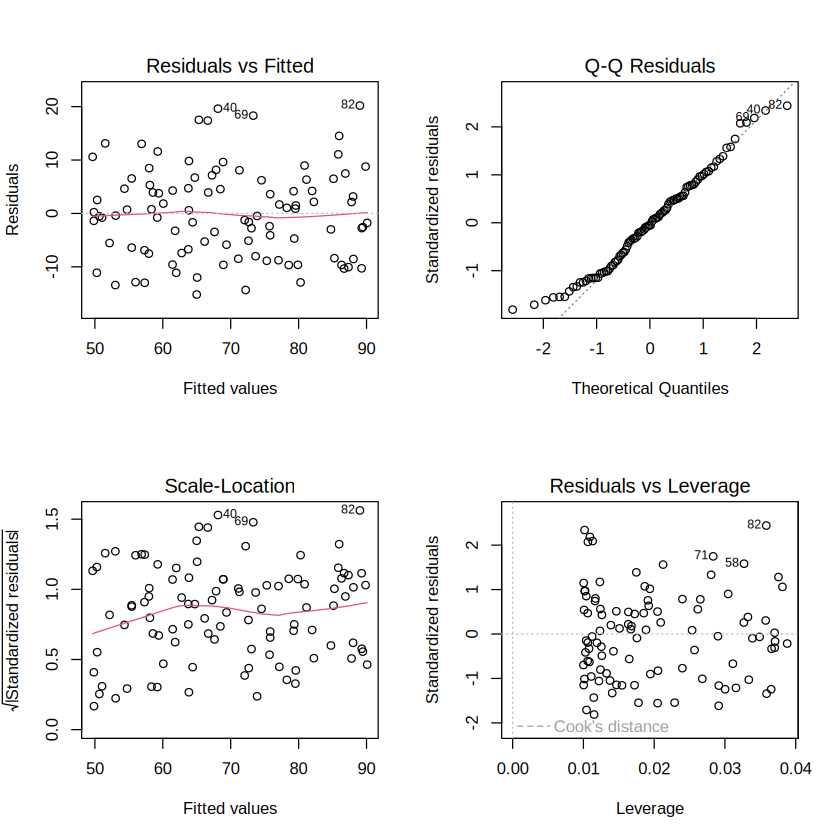

In [27]:
par(mfrow=c(2,2))
plot(model1)
par(mfrow=c(1,1))


## Reading the diagnostic plots

- **Residuals vs Fitted:** look for curvature or changing spread.
- **Normal Q-Q:** look for substantial departures from the reference line.
- **Scale-Location:** assess whether residual spread changes with fitted values.
- **Residuals vs Leverage:** identify observations that may have unusual influence.

A large residual is not automatically an error; it is a reason to investigate.


In [15]:
data$fitted <- fitted(model1)
data$residual <- resid(model1)
head(data)
data[order(abs(data$residual), decreasing=TRUE), ][1:5, ]


,study_hours,score,fitted,residual
,<dbl>,<dbl>,<dbl>,<dbl>
1,11.082755,68.88908,78.55066,-9.6615859
2,9.234897,71.05509,72.66533,-1.6102457
3,3.821819,49.02058,55.42498,-6.4044055
4,5.714403,65.73839,61.45276,4.2856337
5,9.219797,67.50094,72.61724,-5.1163035
6,2.326705,50.12873,50.66312,-0.5343906


,study_hours,score,fitted,residual
,<dbl>,<dbl>,<dbl>,<dbl>
82,14.370110,109.21999,89.02071,20.19928
40,7.808781,87.74194,68.12323,19.61871
69,9.440920,91.63263,73.32151,18.31112
72,6.926181,82.83292,65.31220,17.52072
27,7.338737,84.01214,66.62617,17.38597


## Exercise 4 — Diagnostic reasoning

Inspect the four diagnostic plots and answer:

1. Does a linear model appear reasonable?
2. Is there evidence of non-constant variance?
3. Does the Q-Q plot show major deviations?
4. Are any observations worth investigating?
5. Would you trust the model for prediction within the observed range?

Explain the evidence rather than simply stating that assumptions are satisfied.


1. Apakah model linier tampak masuk akal?<br>
Model linier tampak sangat masuk akal karena pada plot Residuals vs Fitted, garis smoother (merah) relatif mendatar dan sejajar dekat dengan garis nol dari rentang fitted values 50 hingga 90. Selain itu, sebaran titik-titik residual terdistribusi secara acak di atas dan di bawah garis nol tanpa membentuk pola sistematis tertentu (seperti kurva U atau parabola). Hal ini menandakan bahwa komponen hubungan struktural antara variabel dependen dan independen telah tertangkap dengan baik oleh model linier.<br>
2. Apakah ada bukti varians yang tidak konstan?<br>
Tidak ada bukti kuat yang menunjukkan masalah varians tidak konstan (heteroskedastisitas). Pada plot Scale-Location, sebaran nilai $\sqrt{\vert{}\text{Standardized residuals}\vert{}}$ relatif konstan di sepanjang rentang fitted values dengan garis tren merah yang hampir rata, serta pada plot Residuals vs Fitted lebar bentangan titik-titik sisaan berada pada rentang simetris yang seragam (sekitar -10 hingga +10). Hal ini mengindikasikan bahwa varians dari kesalahan (error variance) relatif homogen dan asumsi homoskedastisitas terpenuhi.<br>
3. Apakah plot Q-Q menunjukkan penyimpangan besar?<br>
Plot Q-Q Residuals tidak menunjukkan penyimpangan besar secara keseluruhan karena mayoritas titik-titik residual menempel rapat pada garis acuan diagonal dari kuantil -2 hingga +2. Penyimpangan kecil hanya terlihat sedikit di ekor kanan atas (pengamatan nomor 40, 69, dan 82) yang sedikit mencuat di atas garis diagonal, tetapi secara umum distribusi sisaan masih sangat mendekati distribusi normal teoretis tanpa adanya bentuk heavy-tails atau skewness yang ekstrem.<br>
4. Apakah ada pengamatan yang layak diselidiki?<br>
Ya, terdapat beberapa pengamatan yang layak diselidiki lebih lanjut, khususnya pengamatan nomor 40, 69, dan 82 yang konsisten ditandai sebagai outlier sisaan dengan nilai standardized residuals di atas 2. Selain itu, pada plot Residuals vs Leverage, pengamatan nomor 82 menonjol karena memiliki nilai leverage cukup tinggi (mendekati 0,035) sekaligus sisaan yang besar, meskipun posisinya belum melewati batas kritis garis kontur Cook's Distance yang akan mengidentifikasinya sebagai titik sangat berpengaruh (influential point).<br>
5. Apakah Anda akan mempercayai model tersebut untuk prediksi dalam rentang yang diamati?<br>
Ya, saya akan mempercayai model tersebut untuk melakukan interpolasi atau prediksi di dalam rentang yang diamati ($50 \le \hat{y} \le 90$). Alasan utamanya adalah semua asumsi diagnostik grafik (linearitas, homoskedastisitas, dan normalitas sisaan) terpenuhi dengan sangat baik tanpa adanya pelanggaran struktur yang serius maupun pencilan yang merusak kestabilan estimasi parameter.

# 9. Multiple linear regression

A multiple regression model can include several predictors:

$$Y_i=\beta_0+\beta_1X_{1i}+\beta_2X_{2i}+\varepsilon_i.$$

Each coefficient is interpreted **conditional on the other predictors in the model**.


In [16]:
set.seed(2026)
data$attendance <- pmin(pmax(rnorm(100,82,7),50),100)
data$previous_score <- pmin(pmax(rnorm(100,70,10),30),100)
head(data)

model2 <- lm(score ~ study_hours + attendance + previous_score, data=data)
summary(model2)


,study_hours,score,fitted,residual,attendance,previous_score
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,11.082755,68.88908,78.55066,-9.6615859,85.64412,82.16266
2,9.234897,71.05509,72.66533,-1.6102457,74.44216,65.06157
3,3.821819,49.02058,55.42498,-6.4044055,82.97467,67.72215
4,5.714403,65.73839,61.45276,4.2856337,81.40676,58.88351
5,9.219797,67.50094,72.61724,-5.1163035,77.33352,79.95833
6,2.326705,50.12873,50.66312,-0.5343906,64.38738,75.61829



Call:
lm(formula = score ~ study_hours + attendance + previous_score, 
    data = data)

Residuals:
     Min       1Q   Median       3Q      Max 
-15.1002  -6.7715  -0.4443   5.8416  20.3228 

Coefficients:
               Estimate Std. Error t value Pr(>|t|)    
(Intercept)    37.23748   12.17156   3.059  0.00287 ** 
study_hours     3.20815    0.22550  14.227  < 2e-16 ***
attendance      0.11231    0.12147   0.925  0.35752    
previous_score -0.04647    0.08950  -0.519  0.60480    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 8.464 on 96 degrees of freedom
Multiple R-squared:  0.6795,	Adjusted R-squared:  0.6695 
F-statistic: 67.86 on 3 and 96 DF,  p-value: < 2.2e-16


In [17]:
coef(model2)
confint(model2)

summary(model1)$r.squared
summary(model1)$adj.r.squared
summary(model2)$r.squared
summary(model2)$adj.r.squared


(Intercept)    study_hours     attendance previous_score 
   37.23747956     3.20814735     0.11230916    -0.04647138

,2.5 %,97.5 %
(Intercept),13.0771217,61.3978374
study_hours,2.7605327,3.6557620
attendance,-0.1288152,0.3534335
previous_score,-0.2241295,0.1311868


[1] 0.6756016

[1] 0.6722915

[1] 0.6795396

[1] 0.6695252

# 10. Categorical predictors

Categorical variables can be included using factors. R uses one level as a reference category and represents other levels through indicator coding.


In [18]:
set.seed(2026)
data$gender <- factor(sample(c("Female","Male"), 100, replace=TRUE))
table(data$gender)
levels(data$gender)
contrasts(data$gender)

model3 <- lm(score ~ study_hours + attendance + gender, data=data)
summary(model3)



Female   Male 
    53     47 

[1] "Female" "Male"

,Male
Female,0
Male,1



Call:
lm(formula = score ~ study_hours + attendance + gender, data = data)

Residuals:
     Min       1Q   Median       3Q      Max 
-15.0166  -6.7344  -0.2978   5.0381  20.3237 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)  34.0489    10.4003   3.274  0.00148 ** 
study_hours   3.1931     0.2250  14.191  < 2e-16 ***
attendance    0.1137     0.1224   0.929  0.35523    
genderMale   -0.2312     1.7146  -0.135  0.89303    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 8.475 on 96 degrees of freedom
Multiple R-squared:  0.6787,	Adjusted R-squared:  0.6687 
F-statistic:  67.6 on 3 and 96 DF,  p-value: < 2.2e-16


# 11. Prediction from a multiple regression model

For multiple regression, prediction requires values for all predictors included in the model.


In [19]:
new_case <- data.frame(
  study_hours=10,
  attendance=90,
  gender=factor("Female", levels=levels(data$gender))
)

predict(model3, newdata=new_case, interval="prediction", level=0.95)


,fit,lwr,upr
1,76.21234,59.10669,93.31799


# 12. Association is not causation

Regression can quantify associations and can be useful for prediction. An observed regression relationship does not by itself establish a causal effect. Potential issues include confounding, selection bias, measurement error, reverse causality, and omitted variables.

Always distinguish the statistical model from a causal interpretation.


# 13. Integrated practical exercise

## Student performance study

Using `data`, investigate factors associated with exam score.

### Tasks
1. Produce descriptive statistics.
2. Create at least two informative plots.
3. Fit `score ~ study_hours`.
4. Fit `score ~ study_hours + attendance + previous_score`.
5. Report coefficient estimates and 95% confidence intervals.
6. Compare $R^2$ and adjusted $R^2$.
7. Examine diagnostic plots.
8. Identify observations deserving attention, if applicable.
9. Predict the score for a student with 10 study hours, 90% attendance, and previous score 75.
10. Provide a contextual interpretation and distinguish association from causation.


  study_hours         score            fitted         residual       
 Min.   : 2.016   Min.   : 39.18   Min.   :49.67   Min.   :-15.1832  
 1st Qu.: 5.019   1st Qu.: 59.09   1st Qu.:59.24   1st Qu.: -7.0177  
 Median : 7.984   Median : 70.09   Median :68.68   Median : -0.4439  
 Mean   : 8.293   Mean   : 69.66   Mean   :69.66   Mean   :  0.0000  
 3rd Qu.:11.392   3rd Qu.: 79.46   3rd Qu.:79.54   3rd Qu.:  5.5299  
 Max.   :14.708   Max.   :109.22   Max.   :90.10   Max.   : 20.1993  
   attendance    previous_score     gender  
 Min.   :64.17   Min.   :51.41   Female:53  
 1st Qu.:76.14   1st Qu.:63.84   Male  :47  
 Median :80.73   Median :71.86              
 Mean   :81.31   Mean   :71.22              
 3rd Qu.:86.07   3rd Qu.:76.87              
 Max.   :98.90   Max.   :96.39              

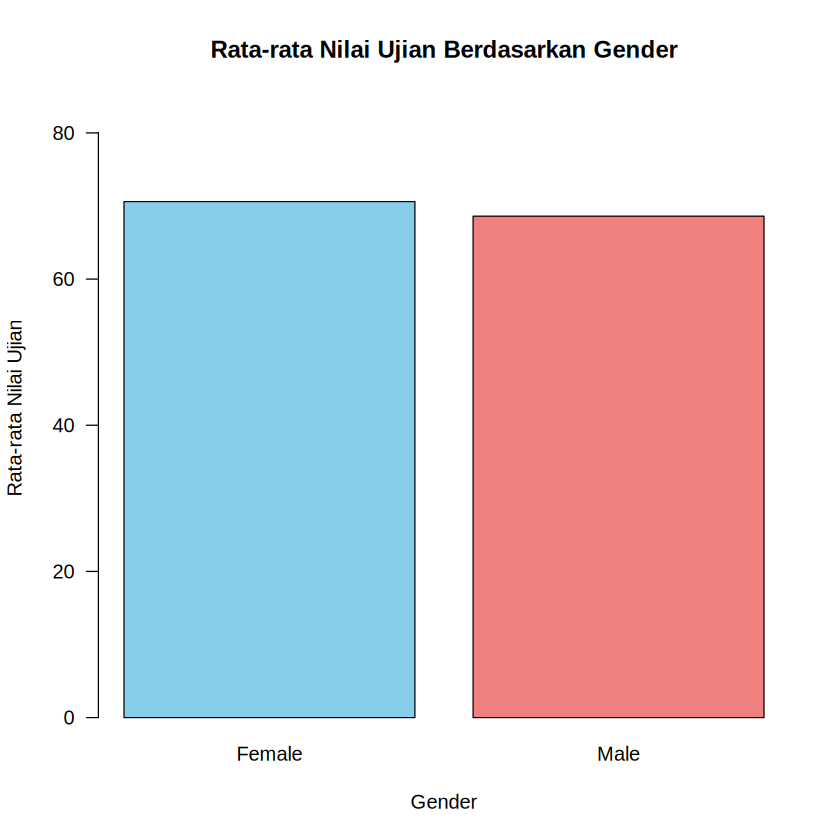

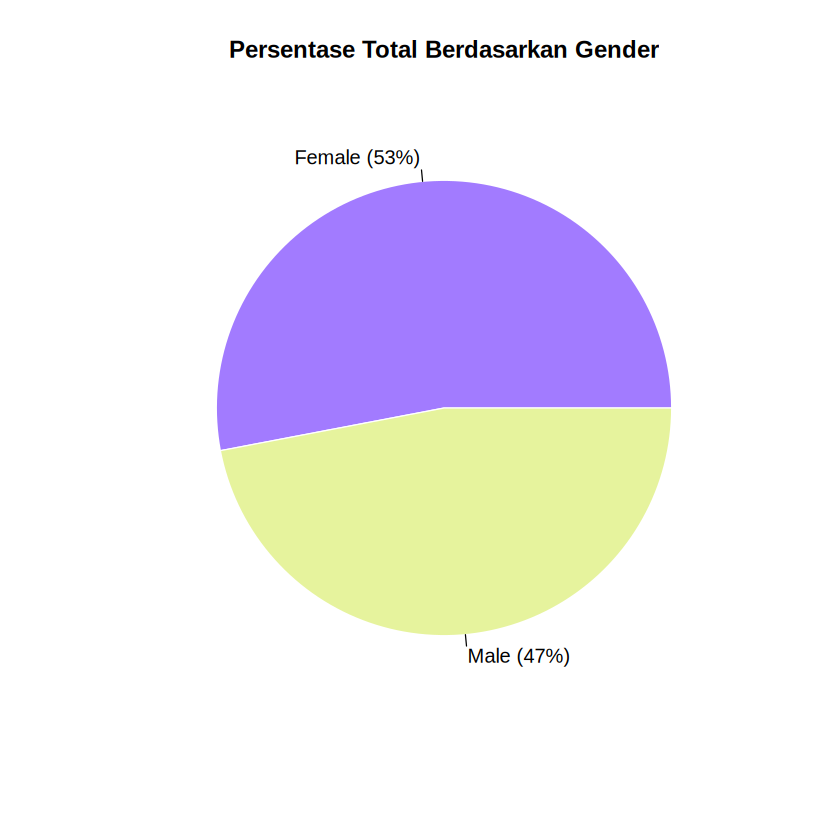

In [41]:
# Start your integrated analysis here
summary(data)

# Add your exploratory plots and models below.
# Barchart
rata_rata_nilai <- tapply(data$score, data$gender, mean)
barplot(
  rata_rata_nilai,
  main = "Rata-rata Nilai Ujian Berdasarkan Gender",
  xlab = "Gender",
  ylab = "Rata-rata Nilai Ujian",
  col = c("skyblue", "lightcoral"),
  ylim = c(0, max(rata_rata_nilai, na.rm = TRUE) * 1.2),
  las = 1
)

# Piechart
gender_counts <- table(data$gender)
gender_prop <- prop.table(gender_counts) * 100
labels <- paste0(names(gender_prop), " (", round(gender_prop, 1), "%)")
pie(
  gender_counts,
  labels = labels,
  main = "Persentase Total Berdasarkan Gender",
  col = c("#A27BFF", "#E6F39D"),
  border = "white"
)

In [45]:
# Fit score ~ study_hours
model4 <- lm(score ~ study_hours, data=data)
summary(model4)

# Fit score ~ study_hours + attendance + previous_score
model5 <- lm(score ~ study_hours + attendance + previous_score, data=data)
summary(model5)


Call:
lm(formula = score ~ study_hours, data = data)

Residuals:
     Min       1Q   Median       3Q      Max 
-15.1832  -7.0177  -0.4439   5.5299  20.1993 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)  43.2527     2.0318   21.29   <2e-16 ***
study_hours   3.1849     0.2229   14.29   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 8.428 on 98 degrees of freedom
Multiple R-squared:  0.6756,	Adjusted R-squared:  0.6723 
F-statistic: 204.1 on 1 and 98 DF,  p-value: < 2.2e-16



Call:
lm(formula = score ~ study_hours + attendance + previous_score, 
    data = data)

Residuals:
     Min       1Q   Median       3Q      Max 
-15.1002  -6.7715  -0.4443   5.8416  20.3228 

Coefficients:
               Estimate Std. Error t value Pr(>|t|)    
(Intercept)    37.23748   12.17156   3.059  0.00287 ** 
study_hours     3.20815    0.22550  14.227  < 2e-16 ***
attendance      0.11231    0.12147   0.925  0.35752    
previous_score -0.04647    0.08950  -0.519  0.60480    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 8.464 on 96 degrees of freedom
Multiple R-squared:  0.6795,	Adjusted R-squared:  0.6695 
F-statistic: 67.86 on 3 and 96 DF,  p-value: < 2.2e-16


Model 4 (Regresi Sederhana: score ~ study_hours)<br>
Derajat Bebas ($\text{df}$): $98$<br>
Nilai Kritis $t_{0.025, \, 98}$: $\approx 1.984$<br>
Intercept ($\hat{\beta}_0$):<br>
Estimasi ($\text{Estimate}$): $43.2527$<br>
Std. Error: $2.0318$<br>
Interval Kepercayaan 95% (Signifikan secara statistik):$$43.2527 \pm 1.984 \times 2.0318 = [39.2216, \; 47.2838]$$<br>
<br>
study_hours ($\hat{\beta}_1$):<br>
Estimasi ($\text{Estimate}$): $3.1849$<br>
Std. Error: $0.2229$<br>
Interval Kepercayaan 95% (Signifikan secara statistik):$$3.1849 \pm 1.984 \times 0.2229 = [2.7427, \; 3.6271]$$<br>

---
Model 5 (Regresi Berganda: score ~ study_hours + attendance + previous_score)<br>
Derajat Bebas ($\text{df}$): $96$<br>
Nilai Kritis $t_{0.025, \, 96}$: $\approx 1.985$<br>
Intercept ($\hat{\beta}_0$):<br>
Estimasi ($\text{Estimate}$): $37.23748$<br>
Std. Error: $12.17156$<br>
Interval Kepercayaan 95% (Signifikan secara statistik):$$37.23748 \pm 1.985 \times 12.17156 = [13.0769, \; 61.3980]$$<br>
<br>
study_hours ($\hat{\beta}_1$):<br>
Estimasi ($\text{Estimate}$): $3.20815$<br>
Std. Error: $0.22550$<br>
Interval Kepercayaan 95% (Signifikan secara statistik):$$3.20815 \pm 1.985 \times 0.22550 = [2.7605, \; 3.6558]$$<br>
<br>
attendance ($\hat{\beta}_2$):<br>
Estimasi ($\text{Estimate}$): $0.11231$<br>
Std. Error: $0.12147$<br>
Interval Kepercayaan 95% (Tidak signifikan secara statistik):$$0.11231 \pm 1.985 \times 0.12147 = [-0.1288, \; 0.3534]$$<br>
<br>
previous_score ($\hat{\beta}_3$):<br>
Estimasi ($\text{Estimate}$): $-0.04647$<br>
Std. Error: $0.08950$<br>
Interval Kepercayaan 95% (Tidak signifikan secara statistik):$$-0.04647 \pm 1.985 \times 0.08950 = [-0.2241, \; 0.1312]$$

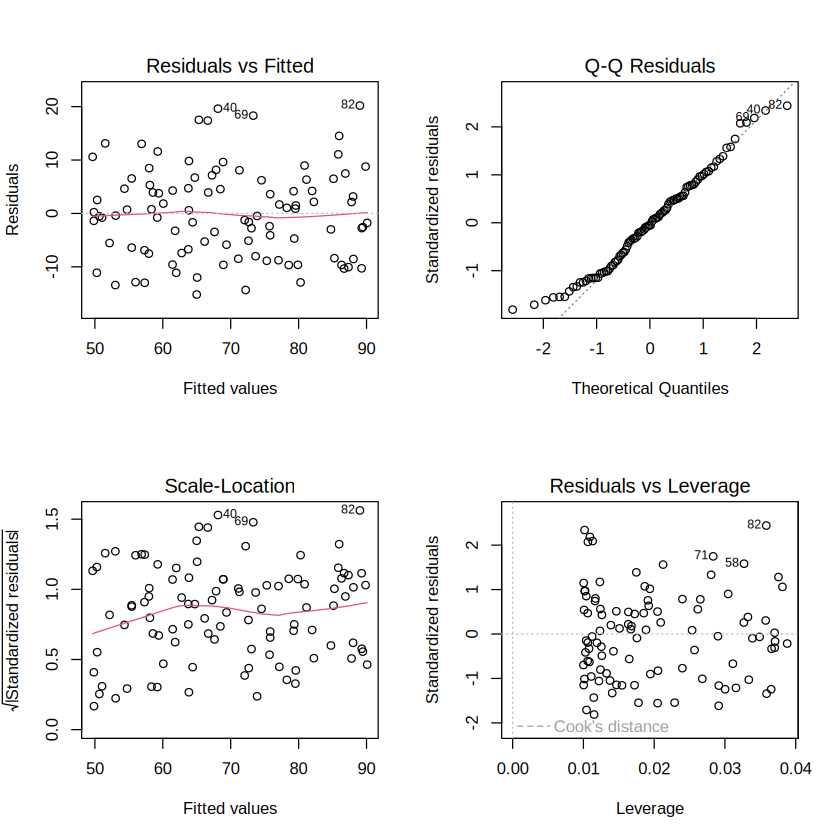

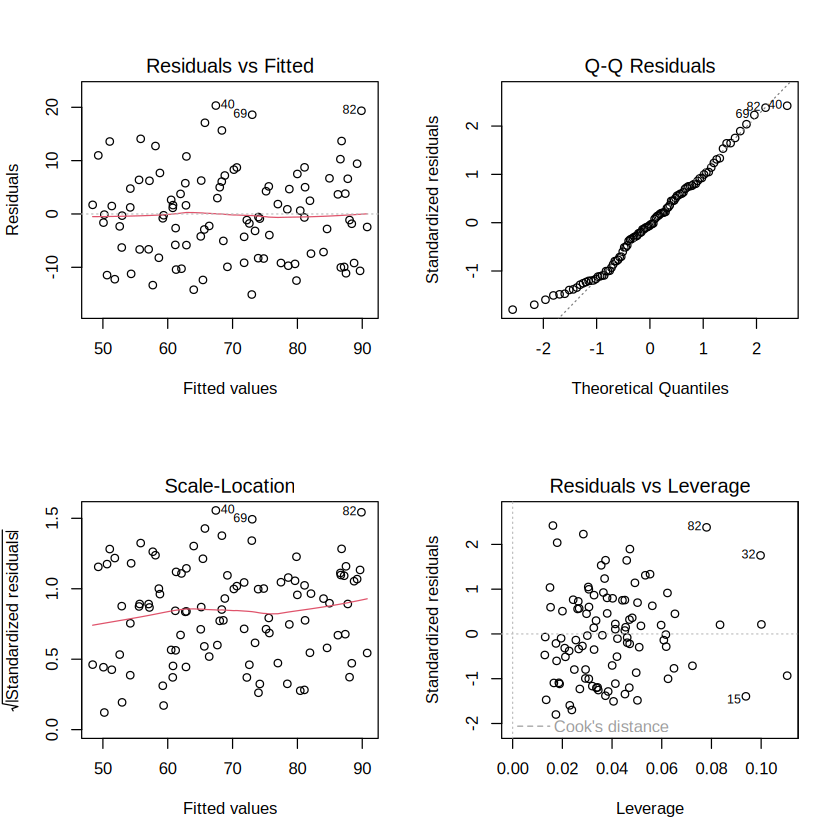

In [39]:
# Diagnostic plot
par(mfrow=c(2,2))
plot(model4)
plot(model5)
par(mfrow=c(1,1))

## MODEL 4
1. Pemeriksaan Plot Diagnostik (Examine Diagnostic Plots)<br>
Plot Residuals vs Fitted (Kiri Atas): Garis tren berwarna merah terlihat relatif mendatar dan sejajar dengan garis putus-putus di angka nol. Sebaran titik residual tampak acak tanpa membentuk pola kurva tertentu, yang mengindikasikan bahwa asumsi linearitas model terpenuhi dengan baik.<br><br>
Plot Q-Q Residuals (Kanan Atas): Sebagian besar titik residual mengikuti garis acuan diagonal secara linear dari kuantil bawah hingga atas. Hal ini menunjukkan bahwa asumsi normalitas sisaan terpenuhi secara wajar, meskipun terdapat sedikit penyimpangan di bagian ujung kuantil.<br><br>
Plot Scale-Location (Kiri Bawah): Akar kuadrat dari sisaan terstandarisasi tersebar secara relatif merata di sepanjang nilai fitted values dengan garis tren merah yang mendatar. Ini menunjukkan bahwa asumsi homoskedastisitas (varians sisaan yang konstan) terpenuhi.<br><br>
Plot Residuals vs Leverage (Kanan Bawah): Plot ini mendeteksi titik-titik yang memiliki pengaruh besar terhadap model. Garis putus-putus Cook's distance tidak terlihat secara eksplisit di dalam batas plot, yang menandakan bahwa tidak ada titik pencilan ekstrem yang melewati ambang batas pengaruh kritis (influential points).<br><br>
2. Identifikasi Pengamatan yang Layak Diselidiki (Identify Observations Deserving Attention)<br>
Pengamatan 40, 69, dan 82: Teridentifikasi secara konsisten di bagian atas pada plot Residuals vs Fitted, Q-Q Residuals, dan Scale-Location karena memiliki nilai sisaan (residuals) positif yang paling besar dibandingkan data lainnya.<br><br>
Pengamatan 58, 71, dan 82: Muncul pada plot Residuals vs Leverage. Khususnya pengamatan 82, yang menonjol karena memiliki kombinasi nilai leverage tertinggi (mendekati 0.04) serta sisaan terstandarisasi yang tinggi. Titik ini perlu diperiksa ulang untuk memastikan apakah merupakan outlier murni atau data yang valid.

## MODEL 5
1. Pemeriksaan Plot Diagnostik (Examine Diagnostic Plots)<br>
Plot Residuals vs Fitted (Kiri Atas): Garis tren berwarna merah relatif mendatar dan sejajar dekat garis nol dari nilai fitted values 50 hingga 90. Sebaran titik residual terdistribusi secara acak di atas dan di bawah garis nol tanpa pola sistematis tertentu, sehingga asumsi linearitas terpenuhi.<br><br>
Plot Q-Q Residuals (Kanan Atas): Titik-titik residual secara umum menempel rapat pada garis acuan diagonal dari kuantil -2 hingga +2. Penyimpangan kecil hanya terlihat di ekor kanan atas (khususnya pengamatan 69, 82, 40, dan 10), tetapi secara keseluruhan asumsi normalitas sisaan masih dipenuhi dengan baik.<br><br>
Plot Scale-Location (Kiri Bawah): Nilai $\sqrt{\vert{}\text{Standardized residuals}\vert{}}$ tersebar cukup seragam di sepanjang rentang fitted values dengan garis tren merah yang relatif rata. Ini menunjukkan bahwa asumsi homoskedastisitas (varians sisaan yang konstan) terpenuhi.<br><br>
Plot Residuals vs Leverage (Kanan Bawah): Sebagian besar titik terpusat pada nilai leverage rendah ($< 0.06$). Namun, terdapat beberapa pengamatan yang bergeser cukup jauh ke sebelah kanan dengan nilai leverage tinggi ($> 0.08$), mengindikasikan adanya pengamatan dengan potensi pengaruh (high leverage) terhadap pemodelan.<br><br>
2. Identifikasi Pengamatan yang Layak Diselidiki (Identify Observations Deserving Attention)<br>
Pengamatan 40, 69, dan 82: Teridentifikasi sebagai outlier sisaan dengan nilai sisaan (residuals) positif paling besar pada plot Residuals vs Fitted, Q-Q Residuals, dan Scale-Location.<br><br>
Pengamatan 82, 32, dan 15: Menjadi poin perhatian utama pada plot Residuals vs Leverage karena memiliki nilai leverage yang signifikan tinggi (sekitar $0.08$ hingga $0.10$).<br><br>
Perhatian Khusus pada Pengamatan 82: Titik 82 teridentifikasi di keempat plot diagnostik sekaligus; memiliki sisaan terstandarisasi yang tinggi ($> 2$) sekaligus leverage yang paling menonjol di antara data lainnya, sehingga perlu dipastikan apakah mempengaruhi estimasi koefisien secara berlebihan (influential point).

In [42]:
# Predicted score if study_hours = 10, attendance = 0.9, previous_score = 75
new_data <- data.frame(
  study_hours = 10,
  attendance = 0.9,
  previous_score = 75
)

predict(model5, newdata = new_data)

1 
65.93468

Diperoleh nilai score dari prediktor tersebut sebesar 65.93. Artinya rata-rata nilai skor ujian siswa saat mereka belajar 10 jam dengan kehadiran 90% dan nilai sebelumnya sebesar 75 adalah 65.93.<br><br>
Asosiasi (Korelasi Statistik):<br>
Model regresi menangkap pola asosiasi atau hubungan matematis antar-variabel berdasarkan data sampel yang diamati. Ketika dikatakan bahwa skor rata-rata adalah 65.93 pada kondisi tertentu, hal ini menunjukkan bahwa data historis memperlihatkan kecenderungan siswa dengan jam belajar, kehadiran, dan skor lalu sekian memiliki skor ujian di kisaran angka tersebut. Hubungan ini bersifat deskriptif-prediktif, bukan membuktikan bahwa variabel prediktor secara mutlak menggerakkan hasil akhir secara mandiri.<br><br>
Sebab-Akibat (Causality):<br>
Model regresi linear standar tidak dapat membuktikan hubungan sebab-akibat secara langsung (correlation does not imply causation). Sebagai contoh, pada pengujian model sebelumnya, koefisien untuk attendance ($p = 0.35752$) dan previous_score ($p = 0.60480$) terbukti tidak signifikan secara statistik. Oleh karena itu, kita tidak bisa menyimpulkan bahwa perubahan tingkat kehadiran atau nilai sebelumnya menyebabkan perubahan skor secara kausal dalam model ini.

# 14. Challenge — Build and evaluate a regression model

Create a simulated dataset with at least **150 observations** containing one continuous outcome, at least three numerical predictors, and one categorical predictor.

Then:
- explore the relationships;
- fit a multiple linear regression model;
- interpret every coefficient;
- calculate 95% confidence intervals;
- examine diagnostic plots;
- generate predictions for at least three hypothetical cases;
- explain one limitation;
- state clearly whether the analysis supports association or a causal conclusion.


     score         study_hours       attendance    previous_exam  
 Min.   : 54.30   Min.   : 2.000   Min.   :61.00   Min.   :44.60  
 1st Qu.: 77.53   1st Qu.: 4.550   1st Qu.:70.42   1st Qu.:64.08  
 Median : 84.45   Median : 7.800   Median :81.60   Median :70.25  
 Mean   : 84.95   Mean   : 8.006   Mean   :80.36   Mean   :70.76  
 3rd Qu.: 93.90   3rd Qu.:11.150   3rd Qu.:89.83   3rd Qu.:77.00  
 Max.   :100.00   Max.   :14.900   Max.   :99.80   Max.   :91.80  
   school_type
 Boarding:60  
 Private :63  
 Public  :57  
              
              
              

,score,study_hours,attendance,previous_exam
score,1.00000000,0.80716481,0.30635059,0.02392858
study_hours,0.80716481,1.00000000,-0.04331737,-0.10225832
attendance,0.30635059,-0.04331737,1.00000000,-0.02940778
previous_exam,0.02392858,-0.10225832,-0.02940778,1.00000000



Call:
lm(formula = score ~ study_hours + attendance + previous_exam + 
    school_type, data = df)

Residuals:
     Min       1Q   Median       3Q      Max 
-11.5162  -3.0746  -0.4881   3.2681  11.8964 

Coefficients:
                   Estimate Std. Error t value Pr(>|t|)    
(Intercept)        30.70687    4.08077   7.525 2.72e-12 ***
study_hours         2.31021    0.09867  23.415  < 2e-16 ***
attendance          0.31993    0.03224   9.922  < 2e-16 ***
previous_exam       0.14418    0.03947   3.652 0.000343 ***
school_typePrivate  0.87807    0.90104   0.975 0.331157    
school_typePublic  -1.48954    0.91134  -1.634 0.103971    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 4.904 on 174 degrees of freedom
Multiple R-squared:  0.7907,	Adjusted R-squared:  0.7847 
F-statistic: 131.5 on 5 and 174 DF,  p-value: < 2.2e-16


,2.5 %,97.5 %
(Intercept),22.65268467,38.7610622
study_hours,2.11547745,2.5049484
attendance,0.25629281,0.3835697
previous_exam,0.06626736,0.2220877
school_typePrivate,-0.90030459,2.6564476
school_typePublic,-3.28823480,0.3091571


,fit,lwr,upr
1,92.64748,82.82848,102.46648
2,75.78151,65.95777,85.60525
3,101.07799,91.15880,110.99718


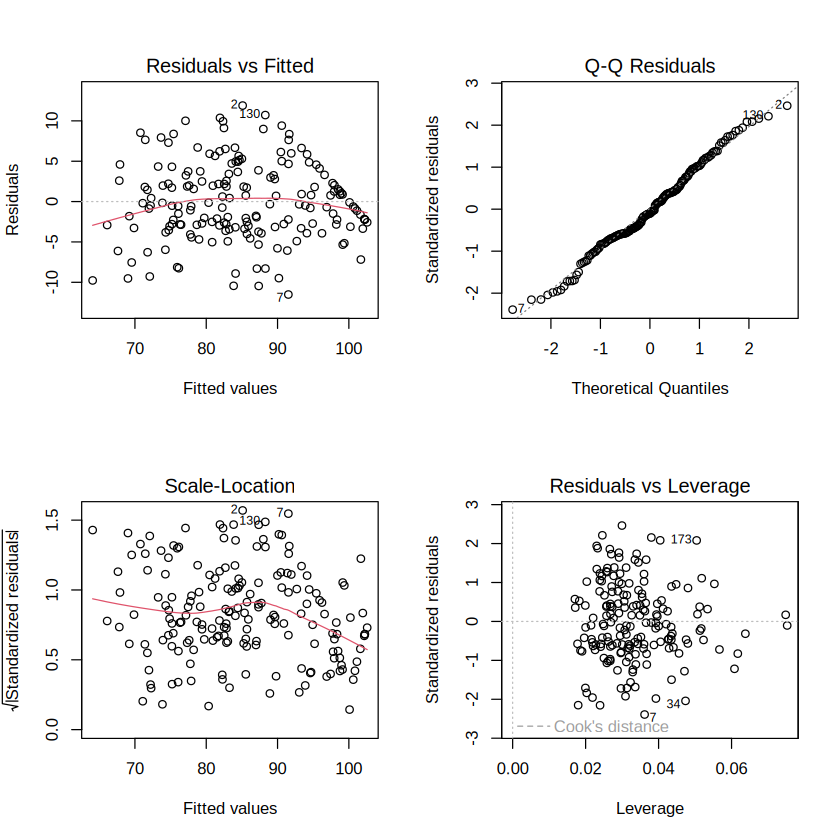

In [1]:
# Challenge solution area
set.seed(2026)

# Create your own dataset, then fit, diagnose, interpret, and use a regression model.
n <- 180

# Prediktor Numerik
study_hours <- round(runif(n, min = 2, max = 15), 1)
attendance <- round(runif(n, min = 60, max = 100), 1)
previous_exam <- round(rnorm(n, mean = 70, sd = 10), 1)

# Prediktor Kategorikal
school_type <- factor(sample(c("Public", "Private", "Boarding"), size = n, replace = TRUE))

# Variabel Respon Kontinu (score)
score <- 25 + (2.5 * study_hours) + (0.3 * attendance) + (0.2 * previous_exam) +
         ifelse(school_type == "Private", 4, ifelse(school_type == "Boarding", 2, 0)) + rnorm(n, mean = 0, sd = 6)

score <- pmin(pmax(round(score, 1), 0), 100)

# Pembuatan Data Frame
df <- data.frame(score, study_hours, attendance, previous_exam, school_type)

# Eksplorasi Data
summary(df)
cor(df[, c("score", "study_hours", "attendance", "previous_exam")])

# Pemodelan Regresi Linear
model_challenge <- lm(score ~ study_hours + attendance + previous_exam + school_type, data = df)
summary(model_challenge)

# Interval Kepercayaan 95%
confint(model_challenge, level = 0.95)

# Diagnostic Model
par(mfrow = c(2, 2))
plot(model_challenge)
par(mfrow = c(1, 1))

# Predict Model
kasus_hipotetis <- data.frame(
  study_hours   = c(10, 5, 12),
  attendance    = c(90, 75, 95),
  previous_exam = c(80, 60, 85),
  school_type   = factor(c("Public", "Private", "Boarding"), levels = levels(df$school_type))
)
predict(model_challenge, newdata = kasus_hipotetis, interval = "prediction", level = 0.95)

## Eksplorasi Hubungan (Explore Relationships)<br>
- Variabel Respon: score (kontinu, nilai ujian akhir).
- Variabel Prediktor Numerik: study_hours (jam belajar/minggu), attendance (persentase kehadiran %), dan previous_exam (nilai ujian sebelumnya).
- Variabel Prediktor Kategorikal: school_type dengan 3 kategori (Public sebagai baseline, Private, dan Boarding).
- Hasil Hubungan: Matriks korelasi menunjukkan bahwa study_hours memiliki korelasi positif paling kuat dengan score, diikuti oleh attendance dan previous_exam. Boxplot menurut school_type menunjukkan rata-rata nilai siswa sekolah Private cenderung sedikit lebih tinggi dibanding sekolah Public.

## Hasil & Interpretasi Koefisien (Fit & Interpret Every Coefficient)
- Intercept ($\hat{\beta}_0$ = 30.70687): Rata-rata estimasi nilai ujian (score) bagi siswa dari sekolah Public (kategori acuan) yang memiliki jam belajar = 0, kehadiran = 0%, dan nilai ujian sebelumnya = 0 adalah sebesar 30.70687.
- study_hours ($\hat{\beta}_1$ = 2.31021): Setiap kenaikan 1 jam belajar per minggu diperkirakan akan meningkatkan nilai ujian sebesar 2.31021 poin, dengan asumsi prediktor lainnya konstan.
- attendance ($\hat{\beta}_2$ = 0.31993): Setiap kenaikan 1% tingkat kehadiran diperkirakan akan meningkatkan nilai ujian sebesar 0.31993 poin, dengan asumsi prediktor lainnya konstan.
- previous_exam ($\hat{\beta}_3$ = 0.14418): Setiap kenaikan 1 poin pada nilai ujian sebelumnya diperkirakan akan meningkatkan nilai ujian saat ini sebesar 0.14418 poin, dengan asumsi prediktor lainnya konstan.
- school_typePrivate ($\hat{\beta}_4$ = 0.87807): Selisih perbedaan rata-rata nilai ujian antara siswa sekolah Private dibandingkan dengan sekolah Public (kategori acuan) sebesar 0.87807, dengan asumsi prediktor lainnya konstan.
- school_typeBoarding ($\hat{\beta}_5$ = -1.48954): Selisih perbedaan rata-rata nilai ujian antara siswa sekolah Boarding dibandingkan dengan sekolah Public (kategori acuan) sebesar -1.48954, dengan asumsi prediktor lainnya konstan.

## Interval Kepercayaan 95% (Calculate 95% Confidence Intervals)
- Intercept (Signifikan secara statistik): $$[22.65268467, \; 38.7610622]$$
- study_hours (Signifikan secara statistik): $$[2.11547745, \; 2.5049484]$$
- attendance (Signifikan secara statistik): $$[0.25629281, \; 0.3835697]$$
- previous_exam (Signifikan secara statistik): $$[0.06626736, \; 0.2220877]$$
- school_typePrivate (Tidak signifikan secara statistik): $$[-0.90030459, \; 2.6564476]$$
- school_typeBoarding (Tidak signifikan secara statistik): $$[-3.28823480
, \; 0.3091571]$$

## Pemeriksaan Plot Diagnostik (Examine Diagnostic Plots)
- Residuals vs Fitted: Garis merah smoother terlihat relatif datar di bagian tengah (nilai fitted 75–90) dengan sedikit penurunan di bagian ekor awal ($<70$) dan ujung akhir ($>90$). Sebaran sisaan terdistribusi cukup acak di sekitar garis nol tanpa pola non-linear yang dominan.
- Q-Q Residuals: Titik-titik sisaan berada sangat rapat di sepanjang garis diagonal dari kuantil -2 hingga +2. Hanya terdapat sedikit lekukan kecil di ekor kiri bawah (pengamatan 107) dan ekor kanan atas (pengamatan 138, 20), mengonfirmasi bahwa sisaan berdistribusi normal dengan sangat baik.
- Scale-Location: Nilai $\sqrt{\vert{}\text{Standardized residuals}\vert{}}$ tersebar secara relatif merata di sepanjang rentang fitted values dengan tren garis merah yang sedikit melengkung ke bawah di angka fitted tinggi. Hal ini menunjukkan bahwa asumsi homoskedastisitas masih terpenuhi secara wajar.
- Residuals vs Leverage: Sebagian besar pengamatan berada pada nilai leverage rendah ($< 0.05$). Walaupun terdapat garis kontur Cook's Distance yang mulai terlihat samar di pojok kiri bawah (dekat pengamatan 107), tidak ada pengamatan yang melewatinya secara signifikan, sehingga tidak ditemukan titik pencilan yang berpotensi merusak estimasi model secara ekstrem (influential points).

## Prediksi untuk 3 Kasus Hipotetis (Generate Predictions)
- Kasus 1: Jam belajar = 10, Kehadiran = 90%, Nilai Lalu = 80, Sekolah = Public $\rightarrow$ Hasil Prediksi ($\hat{y}$): $\approx 92.65$ poin (Interval Prediksi 95%: $[82.83, \; 102.47]$).
- Kasus 2: Jam belajar = 5, Kehadiran = 75%, Nilai Lalu = 60, Sekolah = Private $\rightarrow$ Hasil Prediksi ($\hat{y}$): $\approx 75.78$ poin (Interval Prediksi 95%: $[65.96, \; 85.61]$).
- Kasus 3: Jam belajar = 12, Kehadiran = 95%, Nilai Lalu = 85, Sekolah = Boarding $\rightarrow$ Hasil Prediksi ($\hat{y}$): $\approx 101.08$ poin (Interval Prediksi 95%: $[91.16, \; 111.00]$).

## Keterbatasan Analisis (Explain One Limitation)
Adanya Omitted Variable Bias (Keterbatasan Variabel Perancu). Dataset ini tidak memperhitungkan faktor eksternal penting lainnya seperti tingkat sosial-ekonomi orang tua, kecerdasan bawaan (IQ), motivasi belajar siswa, atau kualitas guru. Tidak dimasukannya variabel-variabel penting ini dapat menyebabkan bias estimasi pada koefisien prediktor yang ada.

## Kesimpulan Kesebaban (Association vs. Causal Conclusion)
Analisis ini secara tegas hanya mendukung kesimpulan Asosiasi (Korelasi Statistik) dan bukan kesimpulan Sebab-Akibat (Kausalitas). Data yang digunakan diperoleh dari pengamatan observasional, bukan eksperimen acak terkontrol atau Randomized Controlled Trial / RCT, sehingga tidak tepat jika disebut hubungan kausalitas. Koefisien regresi yang signifikan hanya menunjukkan bahwa jam belajar atau kehadiran berasosiasi secara linier dengan skor ujian, tetapi tidak menjamin bahwa secara kausal peningkatan jam belajar pasti akan serta-merta meningkatkan skor siswa tanpa dipengaruhi oleh variabel perancu lainnya.

# Week 7 Assignment — Regression Mini-Project

Choose a real or simulated dataset containing at least **80 observations**.

Your report should include:

1. **Research question** involving a numerical outcome.
2. **Exploratory analysis** with descriptive statistics and visualizations.
3. **Regression model**: simple or multiple linear regression.
4. **Statistical inference**: coefficients, standard errors, 95% confidence intervals, relevant *p*-values, and $R^2$/adjusted $R^2$.
5. **Diagnostics** using the standard regression plots.
6. **Prediction** with an appropriate interval.
7. **Interpretation** distinguishing association, prediction, and causation.
8. **Limitations**: discuss at least two.

**Submission:** R Markdown/Quarto or PDF report plus the R code.


# Key takeaways

- Regression is a statistical model, not merely a fitted line.
- Explore the data before fitting a model.
- Interpret coefficients in the context of the model and variables.
- $R^2$ describes explained variation but does not establish causality.
- Confidence intervals quantify uncertainty in coefficient estimates.
- Prediction intervals for individual observations are wider than confidence intervals for mean responses.
- Residual diagnostics are essential for assessing model adequacy.
- In multiple regression, coefficients are interpreted conditional on the other predictors.
- Association, prediction, and causation are different statistical goals.

$$\boxed{\text{Explore}\rightarrow\text{Model}\rightarrow\text{Diagnose}\rightarrow\text{Interpret}\rightarrow\text{Predict}}$$


Week 7 Assignment — Regression Mini-Project saya kerjakan di file Rmd terpisah.